In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

In [12]:
df = pd.read_csv("Car.csv")
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000.0,70000.0,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000.0,50000.0,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000.0,100000.0,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000.0,46000.0,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000.0,141000.0,Diesel,Individual,Manual,Second Owner


In [13]:
print(df.isnull().sum())

name             0
year             0
selling_price    1
km_driven        2
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64


In [3]:
df["selling_price"] = df["selling_price"].fillna(
    df["selling_price"].median()
)
df["km_driven"] = df["km_driven"].fillna(
    df["km_driven"].median()
)

df["fuel"] = df["fuel"].fillna(
    df["fuel"].mode()[0]
)
df["transmission"] = df["transmission"].fillna(
    df["transmission"].mode()[0]
)

df.isnull().sum()


Missing Values After Cleaning:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64


In [4]:
df = df.drop("name", axis=1)

In [14]:
le = LabelEncoder()

df["seller_type"] = le.fit_transform(df["seller_type"])
df["transmission"] = le.fit_transform(df["transmission"])
df = pd.get_dummies(
    df,
    columns=["fuel"],
    prefix="fuel",
    dtype=int
)
owner_mapping = {
    "Fourth & Above Owner": 0,
    "Third Owner": 1,
    "Second Owner": 2,
    "First Owner": 3
}

df["owner"] = df["owner"].map(owner_mapping)

df.head(10)

,name,year,selling_price,km_driven,seller_type,transmission,owner,fuel_CNG,fuel_Diesel,fuel_Electric,fuel_LPG,fuel_Petrol
0,Maruti 800 AC,2007,60000.0,70000.0,1,1,3.0,0,0,0,0,1
1,Maruti Wagon R LXI Minor,2007,135000.0,50000.0,1,1,3.0,0,0,0,0,1
2,Hyundai Verna 1.6 SX,2012,600000.0,100000.0,1,1,3.0,0,1,0,0,0
3,Datsun RediGO T Option,2017,250000.0,46000.0,1,1,3.0,0,0,0,0,1
4,Honda Amaze VX i-DTEC,2014,450000.0,141000.0,1,1,2.0,0,1,0,0,0
5,Maruti Alto LX BSIII,2007,140000.0,125000.0,1,1,3.0,0,0,0,0,1
6,Hyundai Xcent 1.2 Kappa S,2016,550000.0,25000.0,1,1,3.0,0,0,0,0,1
7,Tata Indigo Grand Petrol,2014,240000.0,60000.0,1,1,2.0,0,0,0,0,1
8,Hyundai Creta 1.6 VTVT S,2015,850000.0,25000.0,1,1,3.0,0,0,0,0,1
9,Maruti Celerio Green VXI,2017,365000.0,78000.0,1,1,3.0,1,0,0,0,0


In [6]:
contineous_columns = ["year", "selling_price", "km_driven"]

for column in contineous_columns:
    print("\n", column)
    print("Mean:", df[column].mean())
    print("Median:", df[column].median())
    print("Standard Deviation:", df[column].std())
    print("Minimum:", df[column].min())
    print("Maximum:", df[column].max())


 year
Mean: 2013.0907834101383
Median: 2014.0
Standard Deviation: 4.215343939724197
Minimum: 1992
Maximum: 2020

 selling_price
Mean: 504184.915437788
Median: 350000.0
Standard Deviation: 578520.9346542982
Minimum: 20000.0
Maximum: 8900000.0

 km_driven
Mean: 66240.77511520738
Median: 60000.0
Standard Deviation: 46626.10940534761
Minimum: 1.0
Maximum: 806599.0


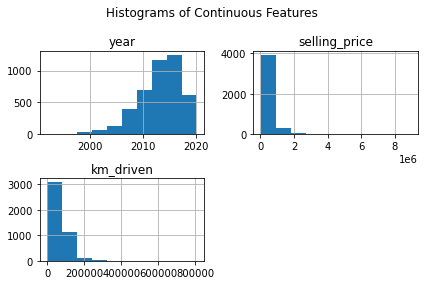

In [7]:
df[contineous_columns].hist()

plt.suptitle("Histograms of Continuous Features")
plt.tight_layout()
plt.show()

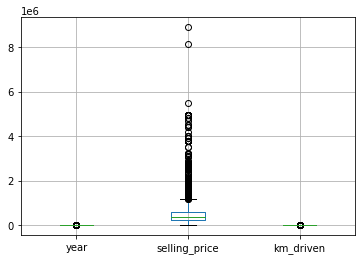

In [11]:
df[contineous_columns].boxplot()
plt.show()

In [9]:
scaler = StandardScaler()

numeric_columns = [
    "year",
    "km_driven"
]

df[numeric_columns] = scaler.fit_transform(
    df[numeric_columns]
)


print("\nDataset after Feature Scaling:")
print(df.head())


Dataset after Feature Scaling:
       year  selling_price  km_driven  seller_type  transmission  owner  \
0 -1.445074        60000.0   0.080634            1             1    3.0   
1 -1.445074       135000.0  -0.348359            1             1    3.0   
2 -0.258795       600000.0   0.724125            1             1    3.0   
3  0.927485       250000.0  -0.434158            1             1    3.0   
4  0.215717       450000.0   1.603562            1             1    2.0   

   fuel_CNG  fuel_Diesel  fuel_Electric  fuel_LPG  fuel_Petrol  
0         0            0              0         0            1  
1         0            0              0         0            1  
2         0            1              0         0            0  
3         0            0              0         0            1  
4         0            1              0         0            0  


In [10]:
X = df.drop("selling_price", axis=1)
y = df["selling_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=15
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (3472, 10)
X_test shape: (868, 10)
y_train shape: (3472,)
y_test shape: (868,)
